# Кейн vs Мбаппе: кто заслужил золотой мяч 2025/26?

**Кто сильнее по цифрам - и насколько ответ зависит от весов.**

Данный отчёт демонстрирует сравнение Харри Кейна и Килиана Мбаппе за сезон 2025/26:
лига, все турниры, командные достижения, дисциплина и итоговый счёт по 100-балльной системе.
Это не претензия на истину или справедливость, а лишь прозрачная модель: все веса и формулы видны,
а чувствительность к ним проверяется отдельно.

Данные: **Understat** (лига 2025/26, пул форвардов, координаты ударов) и
**FBref** (все турниры, дисциплина). Расчёт воспроизводится из локального кэша.

## 0. Как устроен счёт

Итог - 100 баллов, три крупных блока в соответствии с критериями France Football:

| Блок | Вес | Что внутри |
|---|---:|---|
| Индивидуальная статистика (форварды) | **50** | Результативность 20 · Создание моментов 15 · Конверсия 10 · Вовлечённость 5 |
| Командные достижения | **30** | трофеи + индивидуальные награды |
| Фейр-плей | **20** | фолы и карточки на оборонительное действие |

Подблоки статистики:

- **Результативность (Result, 20):** голы без пенальти + ассисты на 90 минут.
- **Создание моментов (Creation, 15):** среднее перцентилей xA/90 и ключевых передач/90.
- **Конверсия (Finishing, 10):** среднее перцентилей «голы − npxG» и конверсии.
- **Вовлечённость (Volume, 5):** удары без пенальти на 90 минут.

Нормировка:

- Статистика - **перцентиль внутри группы из 12 форвардов**: 10 игроков пула + Кейн + Мбаппе;
- Команда и фейр-плей - **доля от суммы двух игроков**. Это сохраняет величину разрыва и не превращает блок в 0/100, как старая min-max нормировка;
- Фейр-плей: `DirtyIndex = 3 × ЖК / оборонительные действия + фолы / оборонительные действия`, чистота = `1 / (1 + DirtyIndex)`.

**Основной пул** - 10 форвардов топ-5 лиг с наибольшим числом голов (без Кейна и Мбаппе).
При равенстве голов выбирается игрок с меньшим числом минут.

**Альтернативный пул** - 10 форвардов с лучшим показателем (голы + ассисты)/90 при минимуме 1500 минут.
Он используется только в проверке чувствительности: важно показать, что выбор пула не меняет победителя.

**Индивидуальный счёт считается по лиге.** Все турниры (Лига чемпионов, кубки, сборная) показаны как контекст:
для них нет полного набора xG/xA в одном источнике, а смешивать лигу и кубки с разным уровнем соперников
в одном перцентиле некорректно.

**Ограничение по ЧМ.** Выгрузки FBref обрезаны на 30.06.2026: плей-офф чемпионата мира,
включая полуфиналы, в матчлогах отсутствует. Обе сборные, что Франция, что Англия, дошли до полуфинала,
поэтому недосчёт симметричен по стадии и не играет большой роли в контексте моего сравнения.
**Карьерные рекорды** (например, «All-time top scorer of France» Мбаппе) в таблице есть, но в счёт не входят:
это рекорд за карьеру, а не за сезон.

In [1]:
import contextlib
import io
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

import metrics
import plots
import scores

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 180)
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")

# Пересобираем все таблицы и графики из локального кэша.
with contextlib.redirect_stdout(io.StringIO()):
    metrics.save_all()
    scores.main()
    FIGURES = plots.plot_all()

print("Пересчёт готов: data/clean/*.csv и figures/*.png обновлены.")

Пересчёт готов: data/clean/*.csv и figures/*.png обновлены.


## 1. Блок индивидуальной статистики

Сезон 2025/26, только лига. Минуты - реальное игровое время, поэтому все показатели приведены к 90 минутам.
Сортировка - по голам без пенальти + ассистам на 90.

In [2]:
metrics_df = pd.read_csv("data/clean/metrics.csv")

columns = {
    "player": "Игрок",
    "league": "Лига",
    "minutes": "Минуты",
    "npg": "Голы без пенальти",
    "assists": "Ассисты",
    "NPG+A_p90": "Гол+пас без пенальти /90",
    "xA_p90": "xA /90",
    "KP_p90": "Ключевые передачи /90",
    "npxG_p90": "npxG /90",
    "NPShots_p90": "Удары без пенальти /90",
    "Conversion": "Конверсия, %",
    "Overperformance": "Голы − npxG",
}

table = metrics_df[list(columns)].rename(columns=columns).copy()
table["Игрок"] = table["Игрок"].replace({"Harry Kane": "Кейн", "Kylian Mbappe": "Мбаппе"})
table = table.sort_values("Гол+пас без пенальти /90", ascending=False).set_index("Игрок")

formats = {
    "Минуты": "{:.0f}",
    "Голы без пенальти": "{:.0f}",
    "Ассисты": "{:.0f}",
    "Гол+пас без пенальти /90": "{:.2f}",
    "xA /90": "{:.2f}",
    "Ключевые передачи /90": "{:.2f}",
    "npxG /90": "{:.2f}",
    "Удары без пенальти /90": "{:.2f}",
    "Конверсия, %": "{:.1f}",
    "Голы − npxG": "{:+.2f}",
}
styled = (
    table.style.format(formats)
    .apply(
        lambda row: ["font-weight: 700; background-color: #FFF6E5" if row.name in ("Кейн", "Мбаппе") else "" for _ in row],
        axis=1,
    )
)
display(styled)

,Лига,Минуты,Голы без пенальти,Ассисты,Гол+пас без пенальти /90,xA /90,Ключевые передачи /90,npxG /90,Удары без пенальти /90,"Конверсия, %",Голы − npxG
Игрок,,,,,,,,,,,
Кейн,Bundesliga,2385,26,5,1.17,0.28,1.51,0.80,4.08,24.1,+4.75
Deniz Undav,Bundesliga,2261,19,6,1.00,0.22,1.51,0.73,4.90,15.4,+0.70
Erling Haaland,EPL,2979,24,8,0.97,0.17,0.76,0.78,3.66,19.8,-1.75
Lautaro Martínez,Serie A,2205,17,6,0.94,0.26,1.51,0.70,3.76,18.5,-0.14
Мбаппе,La liga,2623,17,5,0.75,0.25,2.23,0.66,4.70,12.4,-2.11
Esteban Lepaul,Ligue 1,2761,18,5,0.75,0.11,0.75,0.41,2.71,21.7,+5.31
Patrik Schick,Bundesliga,2005,12,3,0.67,0.14,0.63,0.70,3.01,17.9,-3.63
Serhou Guirassy,Bundesliga,2366,16,1,0.65,0.07,0.76,0.67,3.08,19.8,-1.64
Antoine Semenyo,EPL,3220,16,4,0.56,0.12,1.06,0.32,2.26,19.8,+4.69


Перцентили ниже - те же значения, но в шкале 0-100 внутри группы из 12 форвардов.
100 - лучший результат группы, 0 - худший.

In [3]:
pct_columns = {
    "NPG+A_p90_pct": "Гол+пас /90",
    "xA_p90_pct": "xA /90",
    "KP_p90_pct": "Ключевые передачи /90",
    "npxG_p90_pct": "npxG /90",
    "NPShots_p90_pct": "Удары /90",
    "Conversion_pct": "Конверсия",
    "Overperformance_pct": "Голы − npxG",
}

percentiles = (
    metrics_df.set_index("player")
    .loc[["Harry Kane", "Kylian Mbappe"], list(pct_columns)]
    .rename(columns=pct_columns, index={"Harry Kane": "Кейн", "Kylian Mbappe": "Мбаппе"})
)
percentiles.index.name = "Игрок"

display(percentiles.round(0).astype(int))

,Гол+пас /90,xA /90,Ключевые передачи /90,npxG /90,Удары /90,Конверсия,Голы − npxG
Игрок,,,,,,,
Кейн,100,100,75,100,83,100,92
Мбаппе,67,83,100,50,92,17,33


### Радар: профиль в перцентилях

Кейн — очевидный финишёр: высокая конверсия, лучший результат.
Мбаппе компенсирует это созданием и объёмом: больше ключевых передач и ударов,
но заметно ниже реализация и вклад в голы без пенальти.

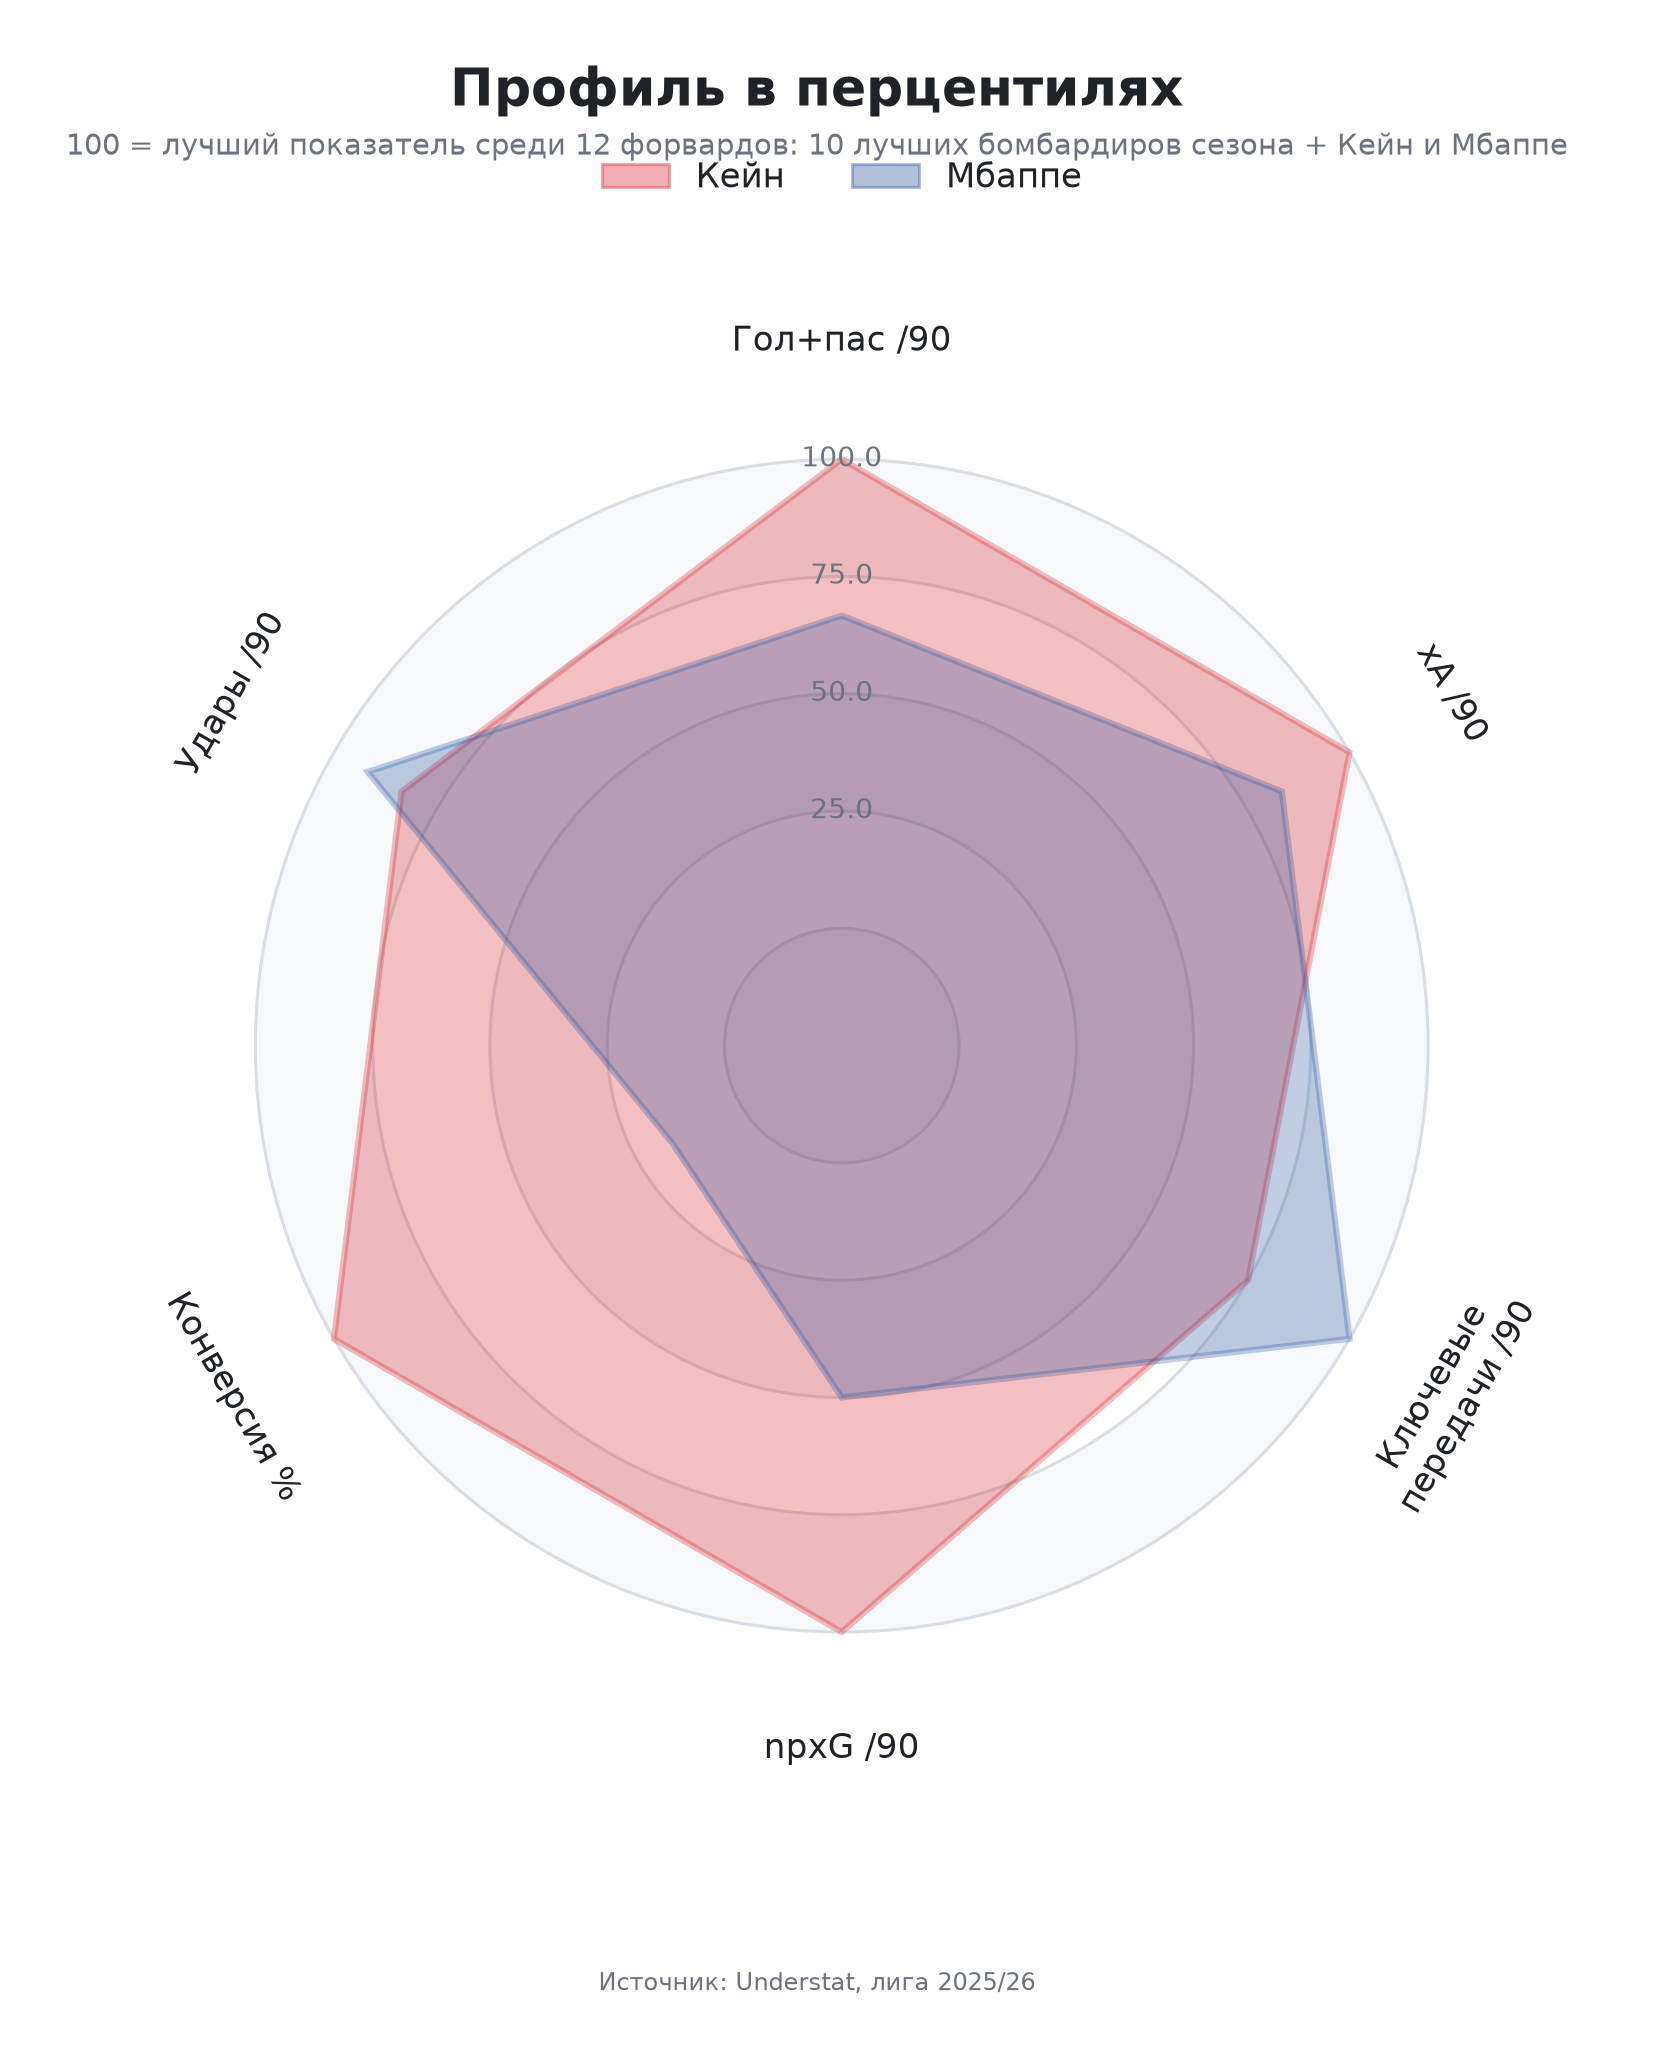

In [4]:
display(Image(filename=str(FIGURES["radar"])))

### Карта ударов

Каждый круг - это удар. Размер круга пропорционален xG удара, цвет - гол или не гол.
Видно разницу в геометрии: Кейн чаще бьёт из центра штрафной, Мбаппе — из левого полупространства
и чаще наносит удары из более острого угла.

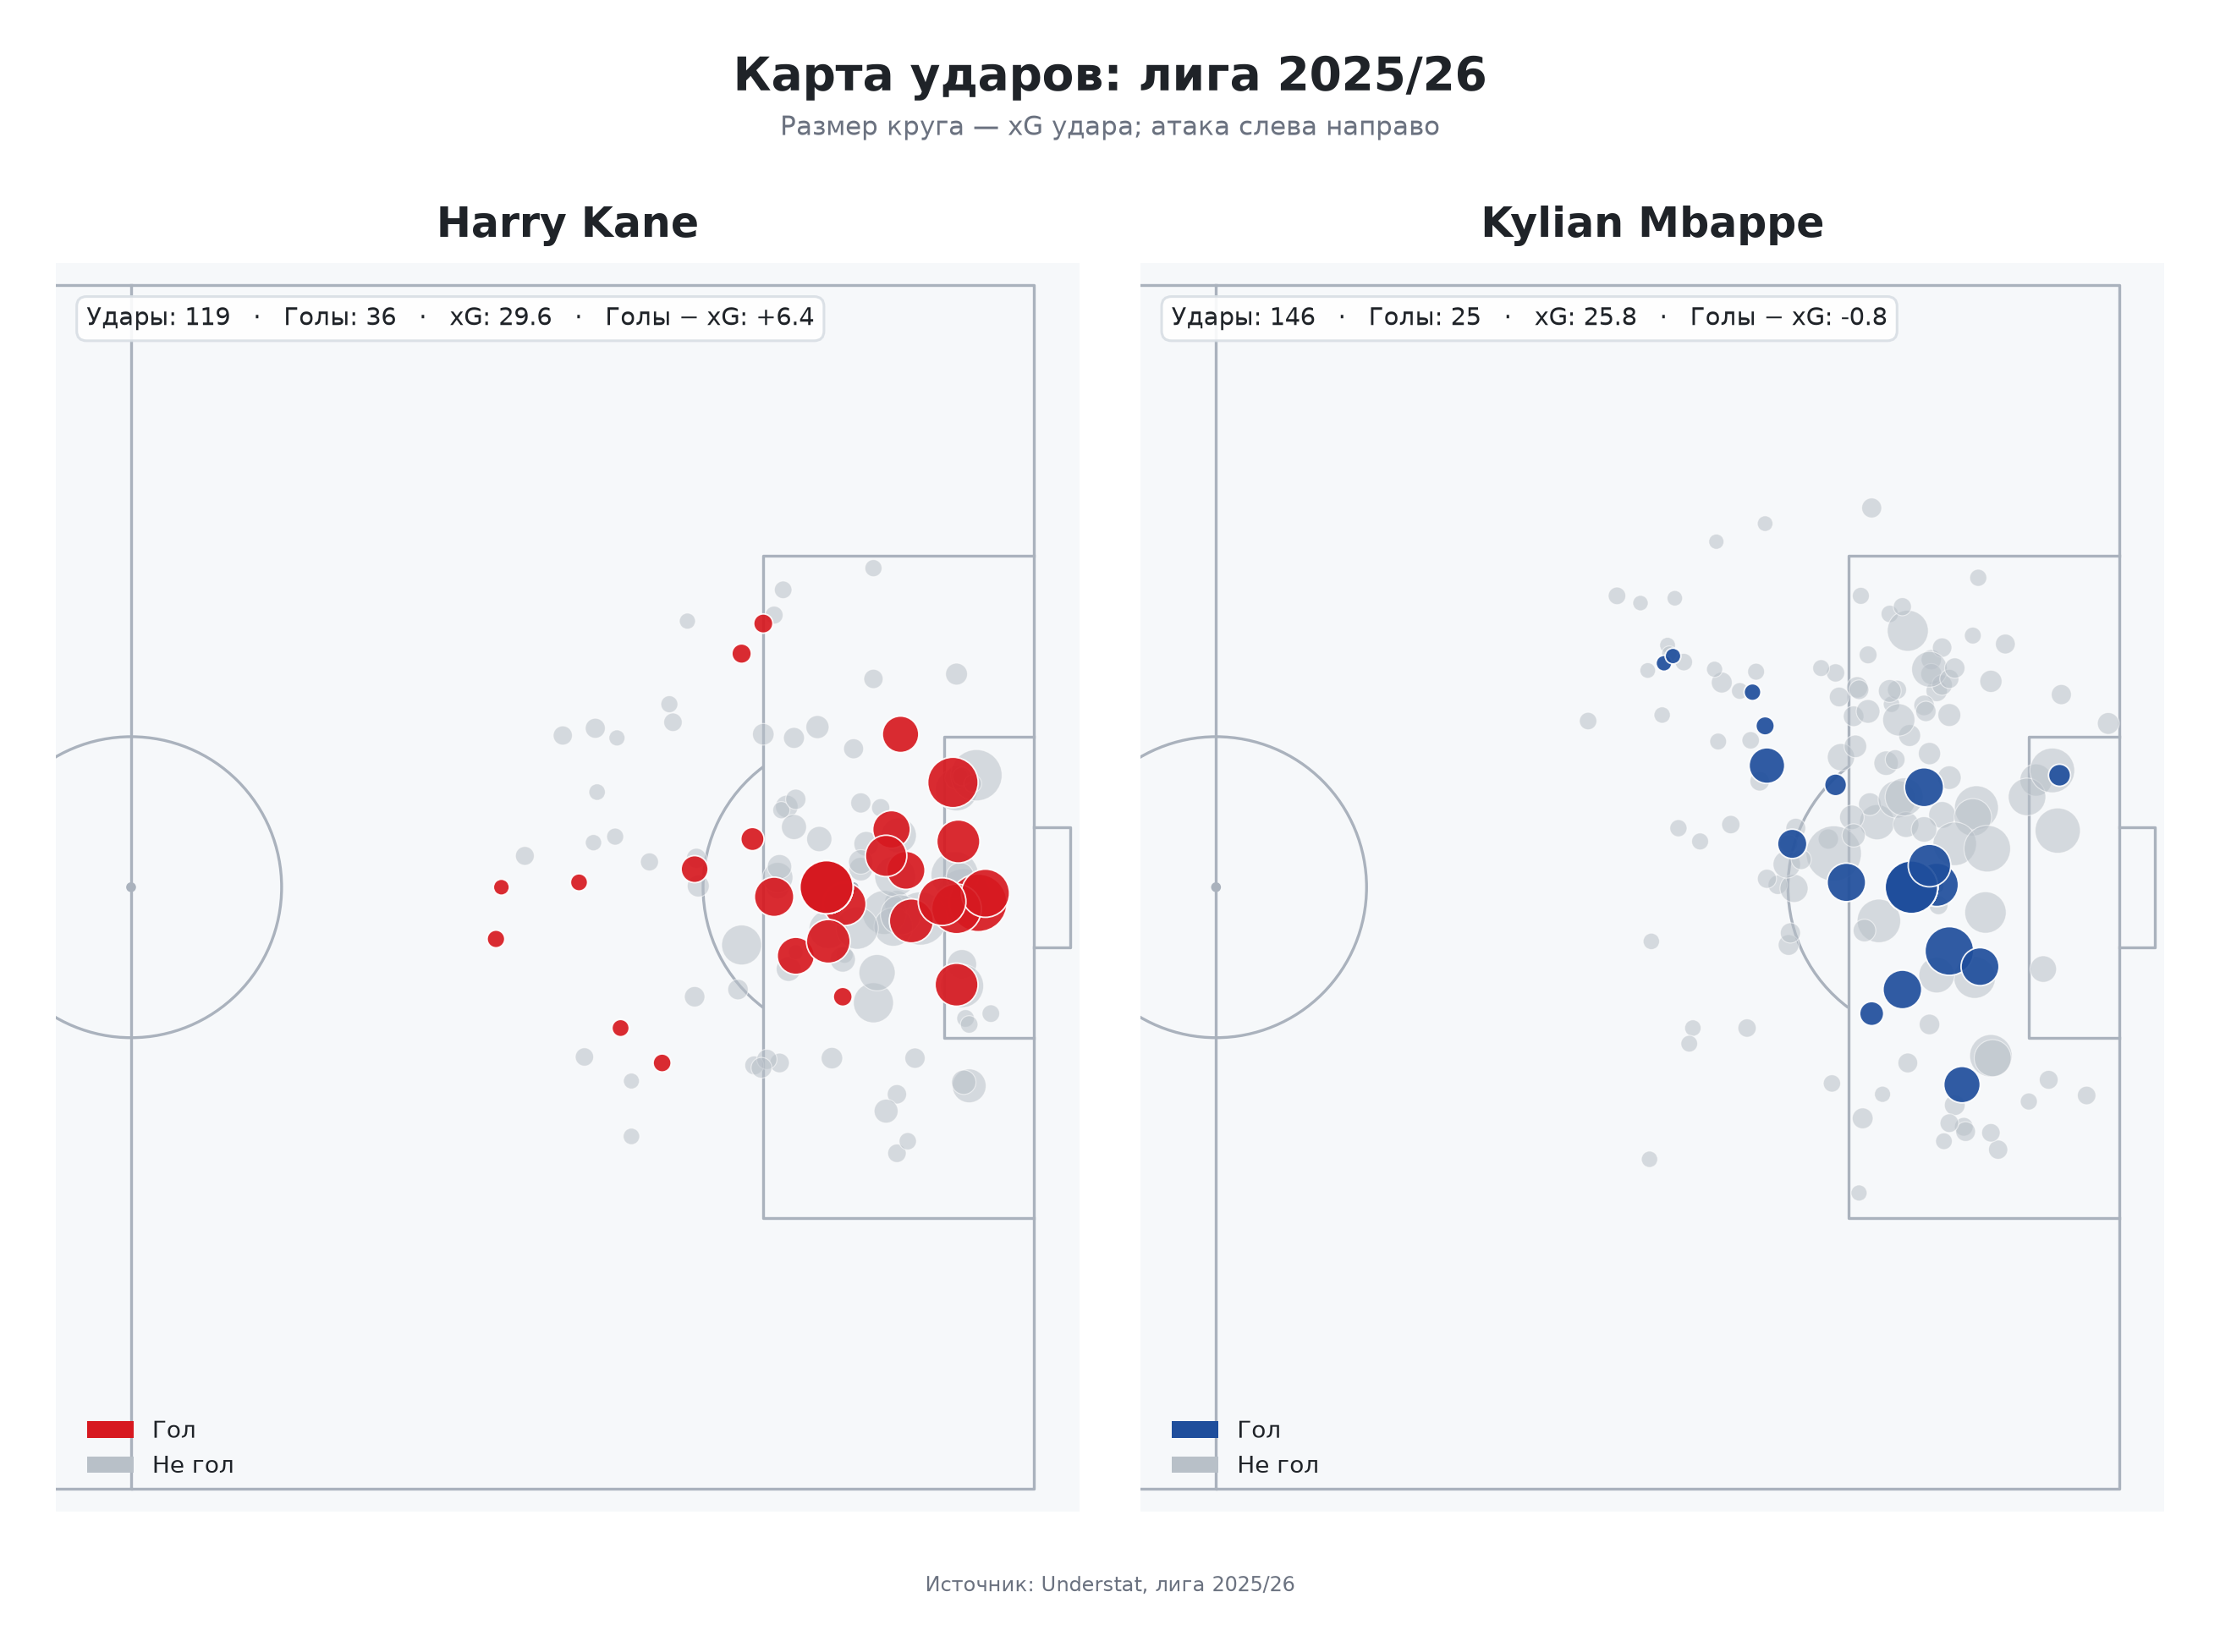

In [5]:
display(Image(filename=str(FIGURES["shot_maps"])))

### Все турниры

Сводка по всем турнирам до 30.06.2026. Голы без пенальти: у Кейна больше,
у Мбаппе больше ассистов и ударов. Эти цифры не входят в индивидуальный счёт. Это контекст всего сезона, который показывает, что выборка по лиге не искажает данные: игроки сохраняют преимущество над оппонентом ровно в тех же показателях, что и в пересчёте только на лигу.

In [6]:
all_comps = pd.read_csv("data/clean/all_comps.csv", index_col=0).T
all_comps.columns = ["Кейн", "Мбаппе"]
all_comps.index = [
    "Матчи", "Минуты", "Голы", "Пенальти", "Голы без пенальти", "Ассисты",
    "Гол+пас без пенальти", "Гол+пас без пенальти /90", "Голы /90", "Ассисты /90",
    "Удары", "Удары /90", "ЖК", "КК", "Фолы", "Отборы", "Перехваты",
    "Первый матч", "Последний матч",
]
display(all_comps)

,Кейн,Мбаппе
Матчи,62,59
Минуты,4908,4667
Голы,70,55
Пенальти,19,14
Голы без пенальти,51,41
Ассисты,7,11
Гол+пас без пенальти,58,52
Гол+пас без пенальти /90,1.06,1.00
Голы /90,1.28,1.06
Ассисты /90,0.13,0.21


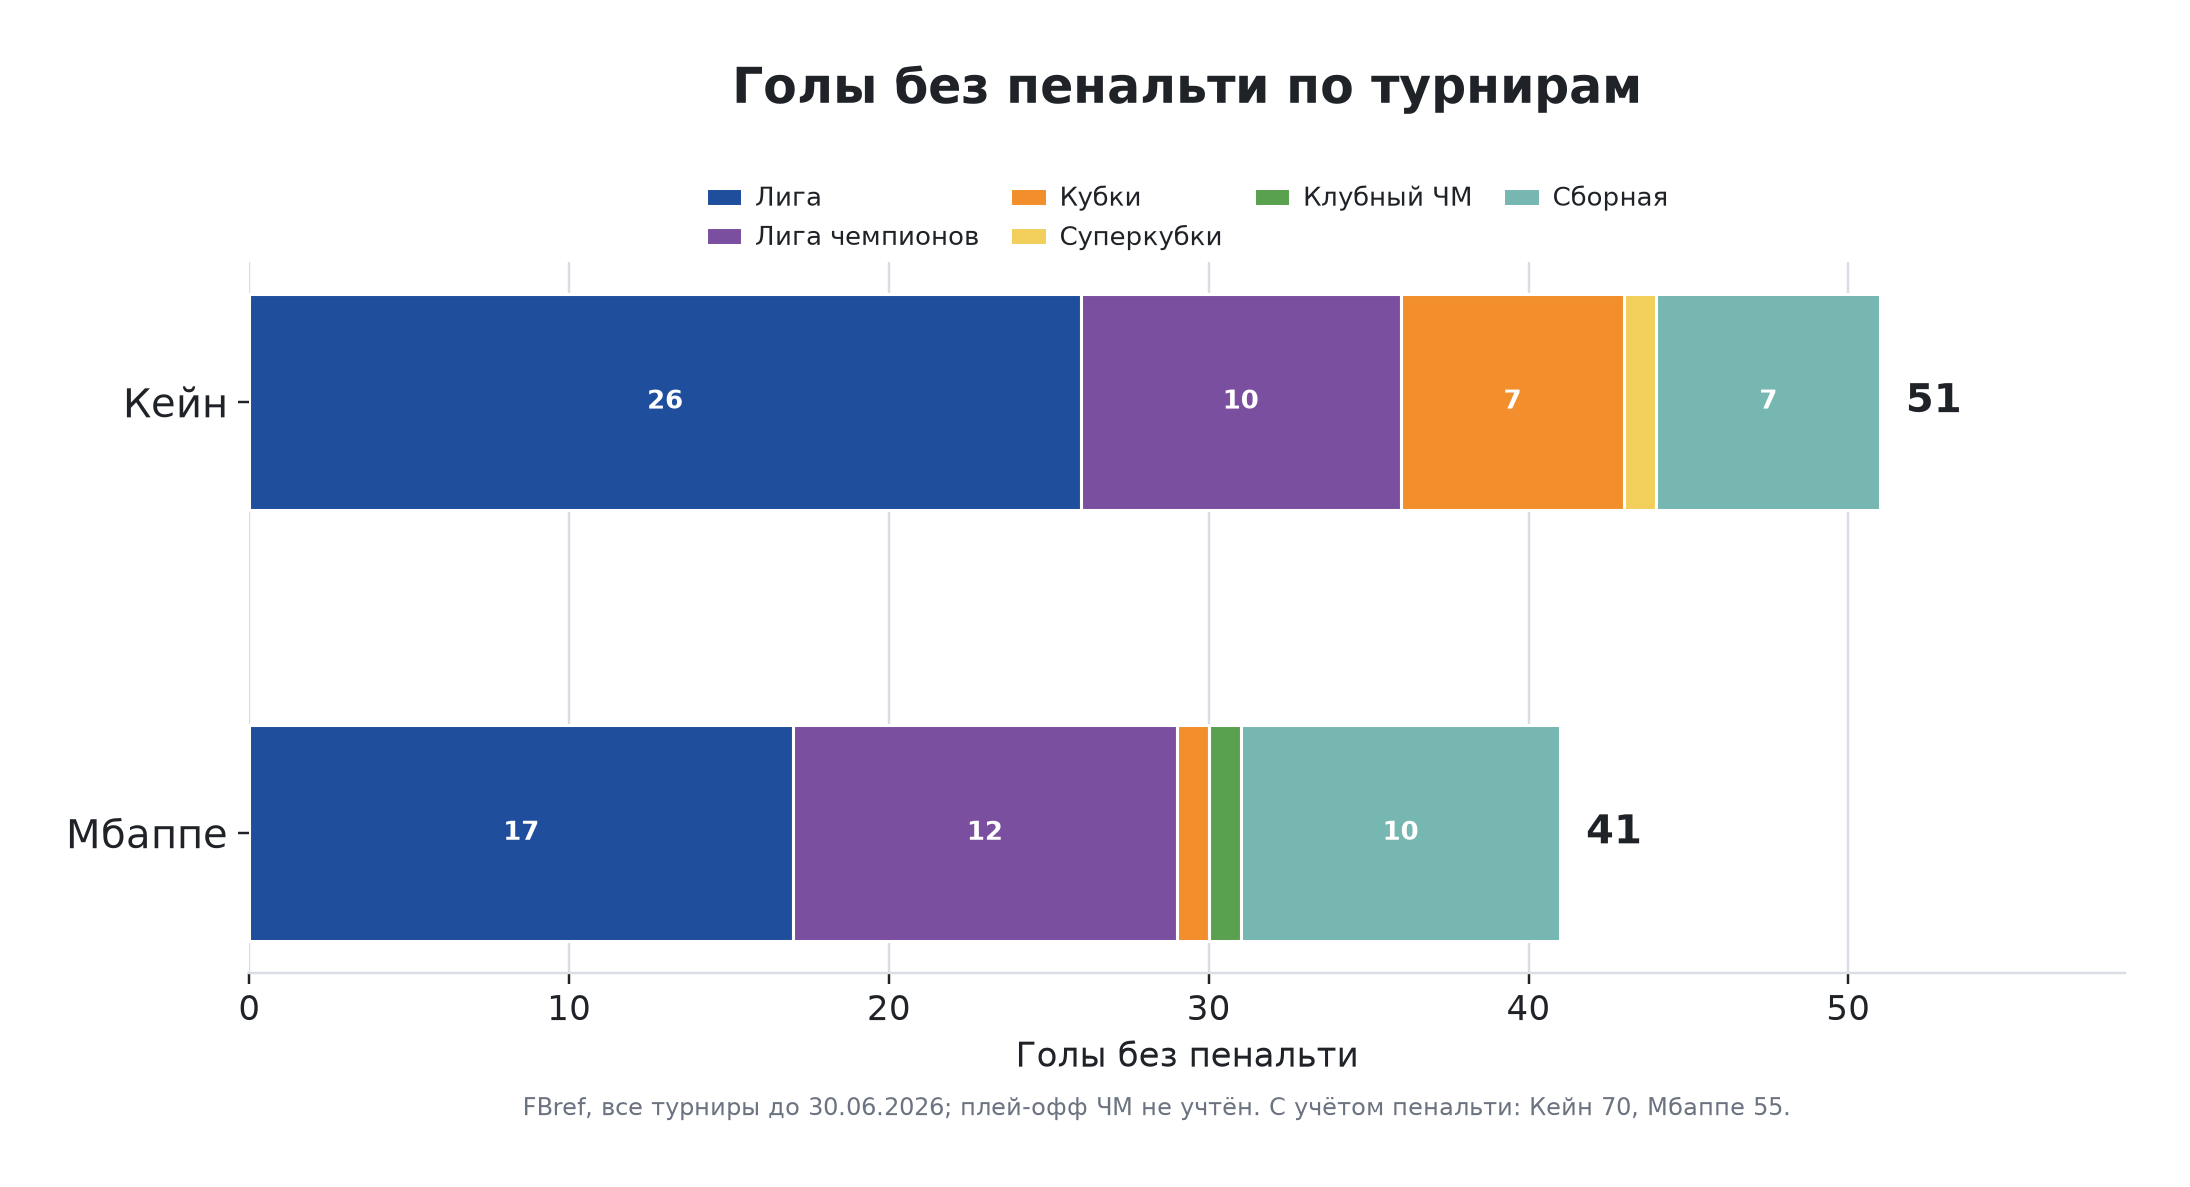

In [7]:
display(Image(filename=str(FIGURES["goals_by_competition"])))

## 2. Блок командных и индивидуальных достижений

Блок достижений - это не «кто больше выиграл», а сумма двух вещей:

- **трофеи**: Бундеслига (3), Кубок Германии (2), Суперкубок Германии (1),
  Ла Лига (3), Лига чемпионов (3), клубный ЧМ (2), Суперкубок (1), ЧМ (3);
- **индивидуальные награды**: «Золотая бутса» (3), лучший игрок (2), лучший бомбардир (2), прочее (1).

Карьерные рекорды в счёт не идут. Сырые очки затем переводятся в долю от суммы двух игроков.

In [8]:
team = pd.read_csv("data/clean/team_points.csv", index_col=0)
team.index = ["Кейн", "Мбаппе"]
team = team.rename(columns={
    "trophies": "Очки за трофеи",
    "awards": "Очки за награды",
    "total": "Всего",
    "Team_pct": "Доля, %",
})
for column in ["Очки за трофеи", "Очки за награды", "Всего"]:
    team[column] = team[column].astype(int)
display(team.round(1))

details = pd.read_csv("data/clean/team_details.csv")
counted = details[details["counted"]].copy()
counted["player"] = counted["player"].replace({"Harry Kane": "Кейн", "Kylian Mbappe": "Мбаппе"})
counted = counted.rename(columns={"player": "Игрок", "type": "Тип", "item": "Достижение", "points": "Баллы"})
counted["Тип"] = pd.Categorical(counted["Тип"], ["Трофей", "Награда"], ordered=True)
counted["Баллы"] = counted["Баллы"].astype(int)
display(
    counted[["Игрок", "Тип", "Достижение", "Баллы"]]
    .sort_values(["Игрок", "Тип", "Баллы"], ascending=[True, True, False])
    .set_index(["Игрок", "Тип"])
)

,Очки за трофеи,Очки за награды,Всего,"Доля, %"
Кейн,6,7,13,61.90
Мбаппе,0,8,8,38.10


Достижение  Баллы
Игрок  Тип                                         
Кейн   Трофей                     Bundesliga      3
       Трофей                     German Cup      2
       Трофей                   DFL-Supercup      1
       Награда          European Golden Shoe      3
       Награда        Best player Bundesliga      2
       Награда         Top scorer Bundesliga      2
Мбаппе Награда         Golden Boot World Cup      3
       Награда  Golden Boot Champions League      3
       Награда            Top scorer La Liga      2

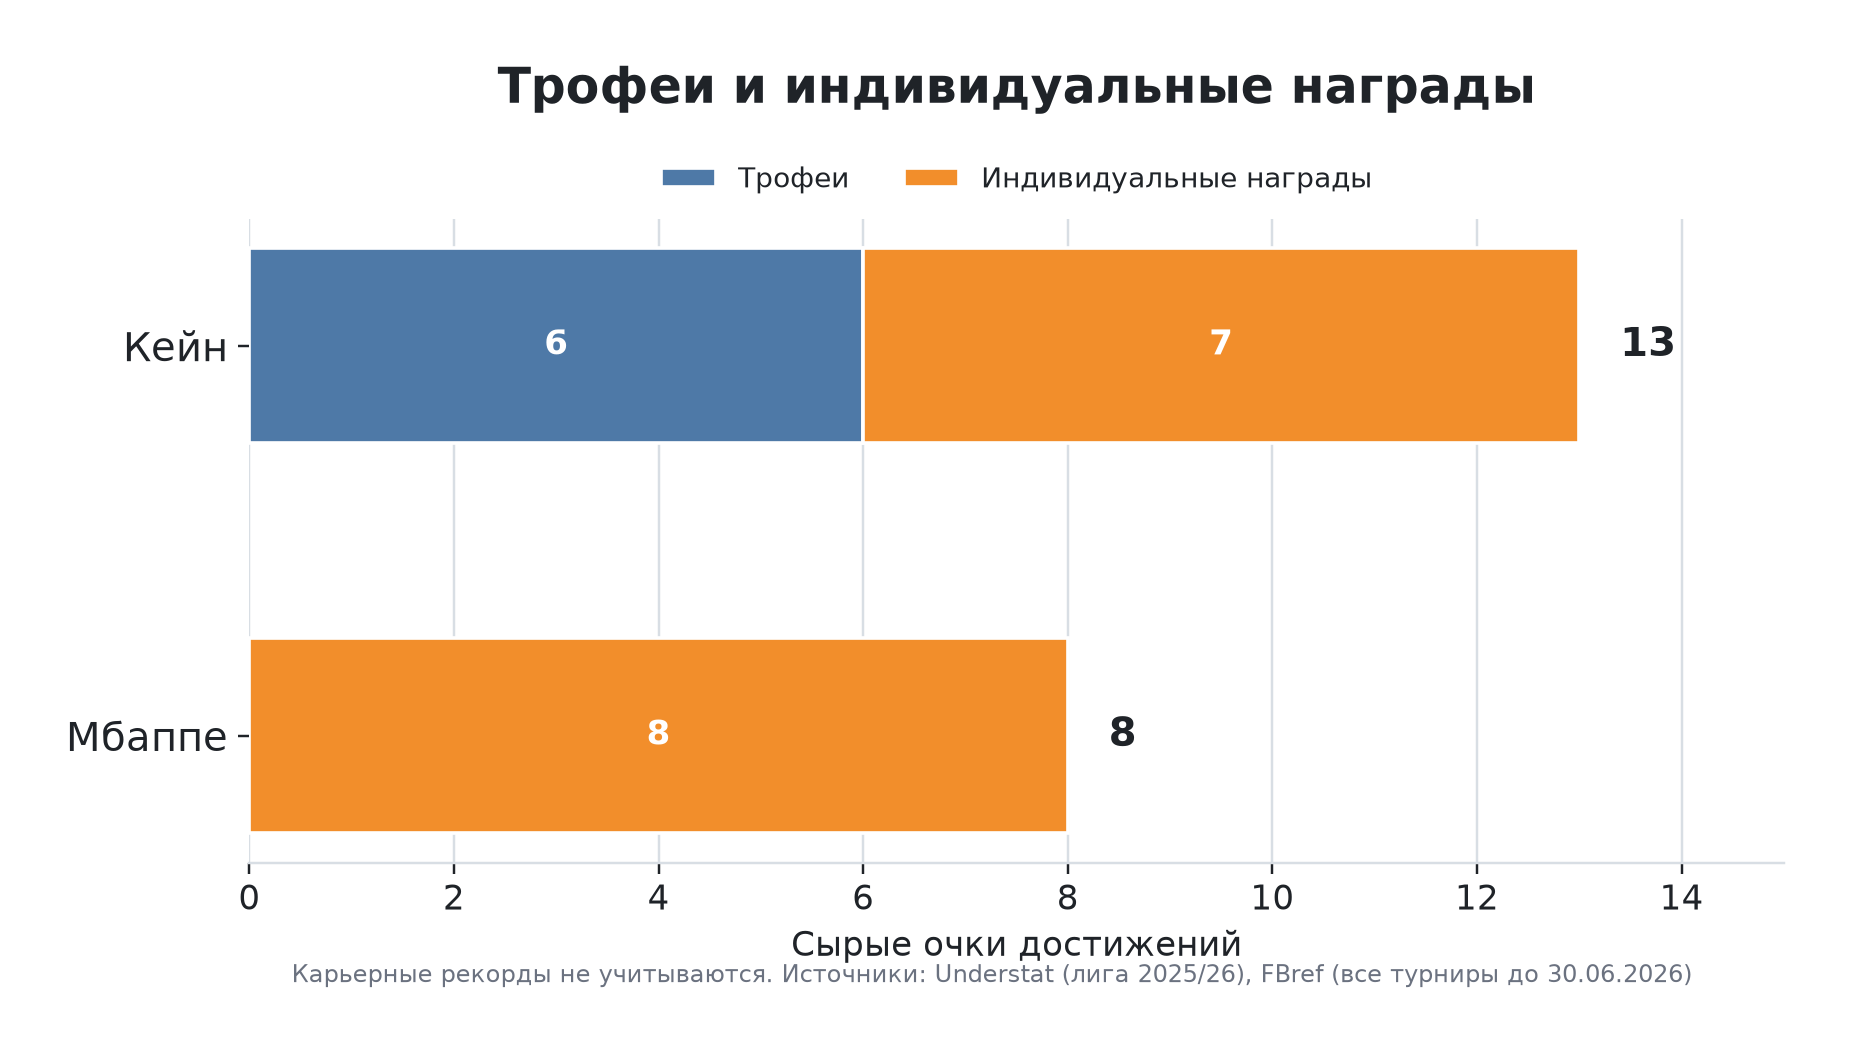

In [9]:
display(Image(filename=str(FIGURES["team_points"])))

## 3. Блок фейр-плей и почему считаем на оборонительное действие

Абсолютные фолы и карточки несправедливы к игроку, который много отрабатывает без мяча.
Мбаппе фолит реже Кейна (24 против 48), но и вступает в отбор/перехват гораздо реже (10 против 35).
На каждое оборонительное действие у Мбаппе приходится 2.4 фола и 0.8 ЖК,
у Кейна - 1.37 фола и 0.09 ЖК.

Поэтому индекс «грязности» нормируется на оборонительные действия, а карточка весит втрое больше фола:
`3 × ЖК / действия + фолы / действия`. Чем ниже индекс, тем чище игра в пересчёте на реальную оборонительную работу. Другими словами: индекс помогает понять, за то на самом деле игроки получают дисциплинарные наказания - за оплошности при отработке сзади, или же за непозволительное поведение на поле и за его пределами.

In [10]:
fair_play = pd.read_csv("data/clean/fair_play_scores.csv", index_col=0)
fair_play.index = ["Кейн", "Мбаппе"]
fair_play = fair_play[[
    "CrdY", "Fls", "DefActions", "Fls_p90", "CrdY_p90", "DefActions_p90",
    "Fls_per_DA", "CrdY_per_DA", "DirtyIndex", "FairPlay_pct",
]].rename(columns={
    "CrdY": "ЖК",
    "Fls": "Фолы",
    "DefActions": "Обор. действия",
    "Fls_p90": "Фолы /90",
    "CrdY_p90": "ЖК /90",
    "DefActions_p90": "Обор. действия /90",
    "Fls_per_DA": "Фолы на действие",
    "CrdY_per_DA": "ЖК на действие",
    "DirtyIndex": "DirtyIndex",
    "FairPlay_pct": "Доля чистоты, %",
})
display(fair_play.round(2))

,ЖК,Фолы,Обор. действия,Фолы /90,ЖК /90,Обор. действия /90,Фолы на действие,ЖК на действие,DirtyIndex,"Доля чистоты, %"
Кейн,3,48,35,0.88,0.06,0.64,1.37,0.09,1.63,68.80
Мбаппе,8,24,10,0.46,0.15,0.19,2.40,0.80,4.80,31.20


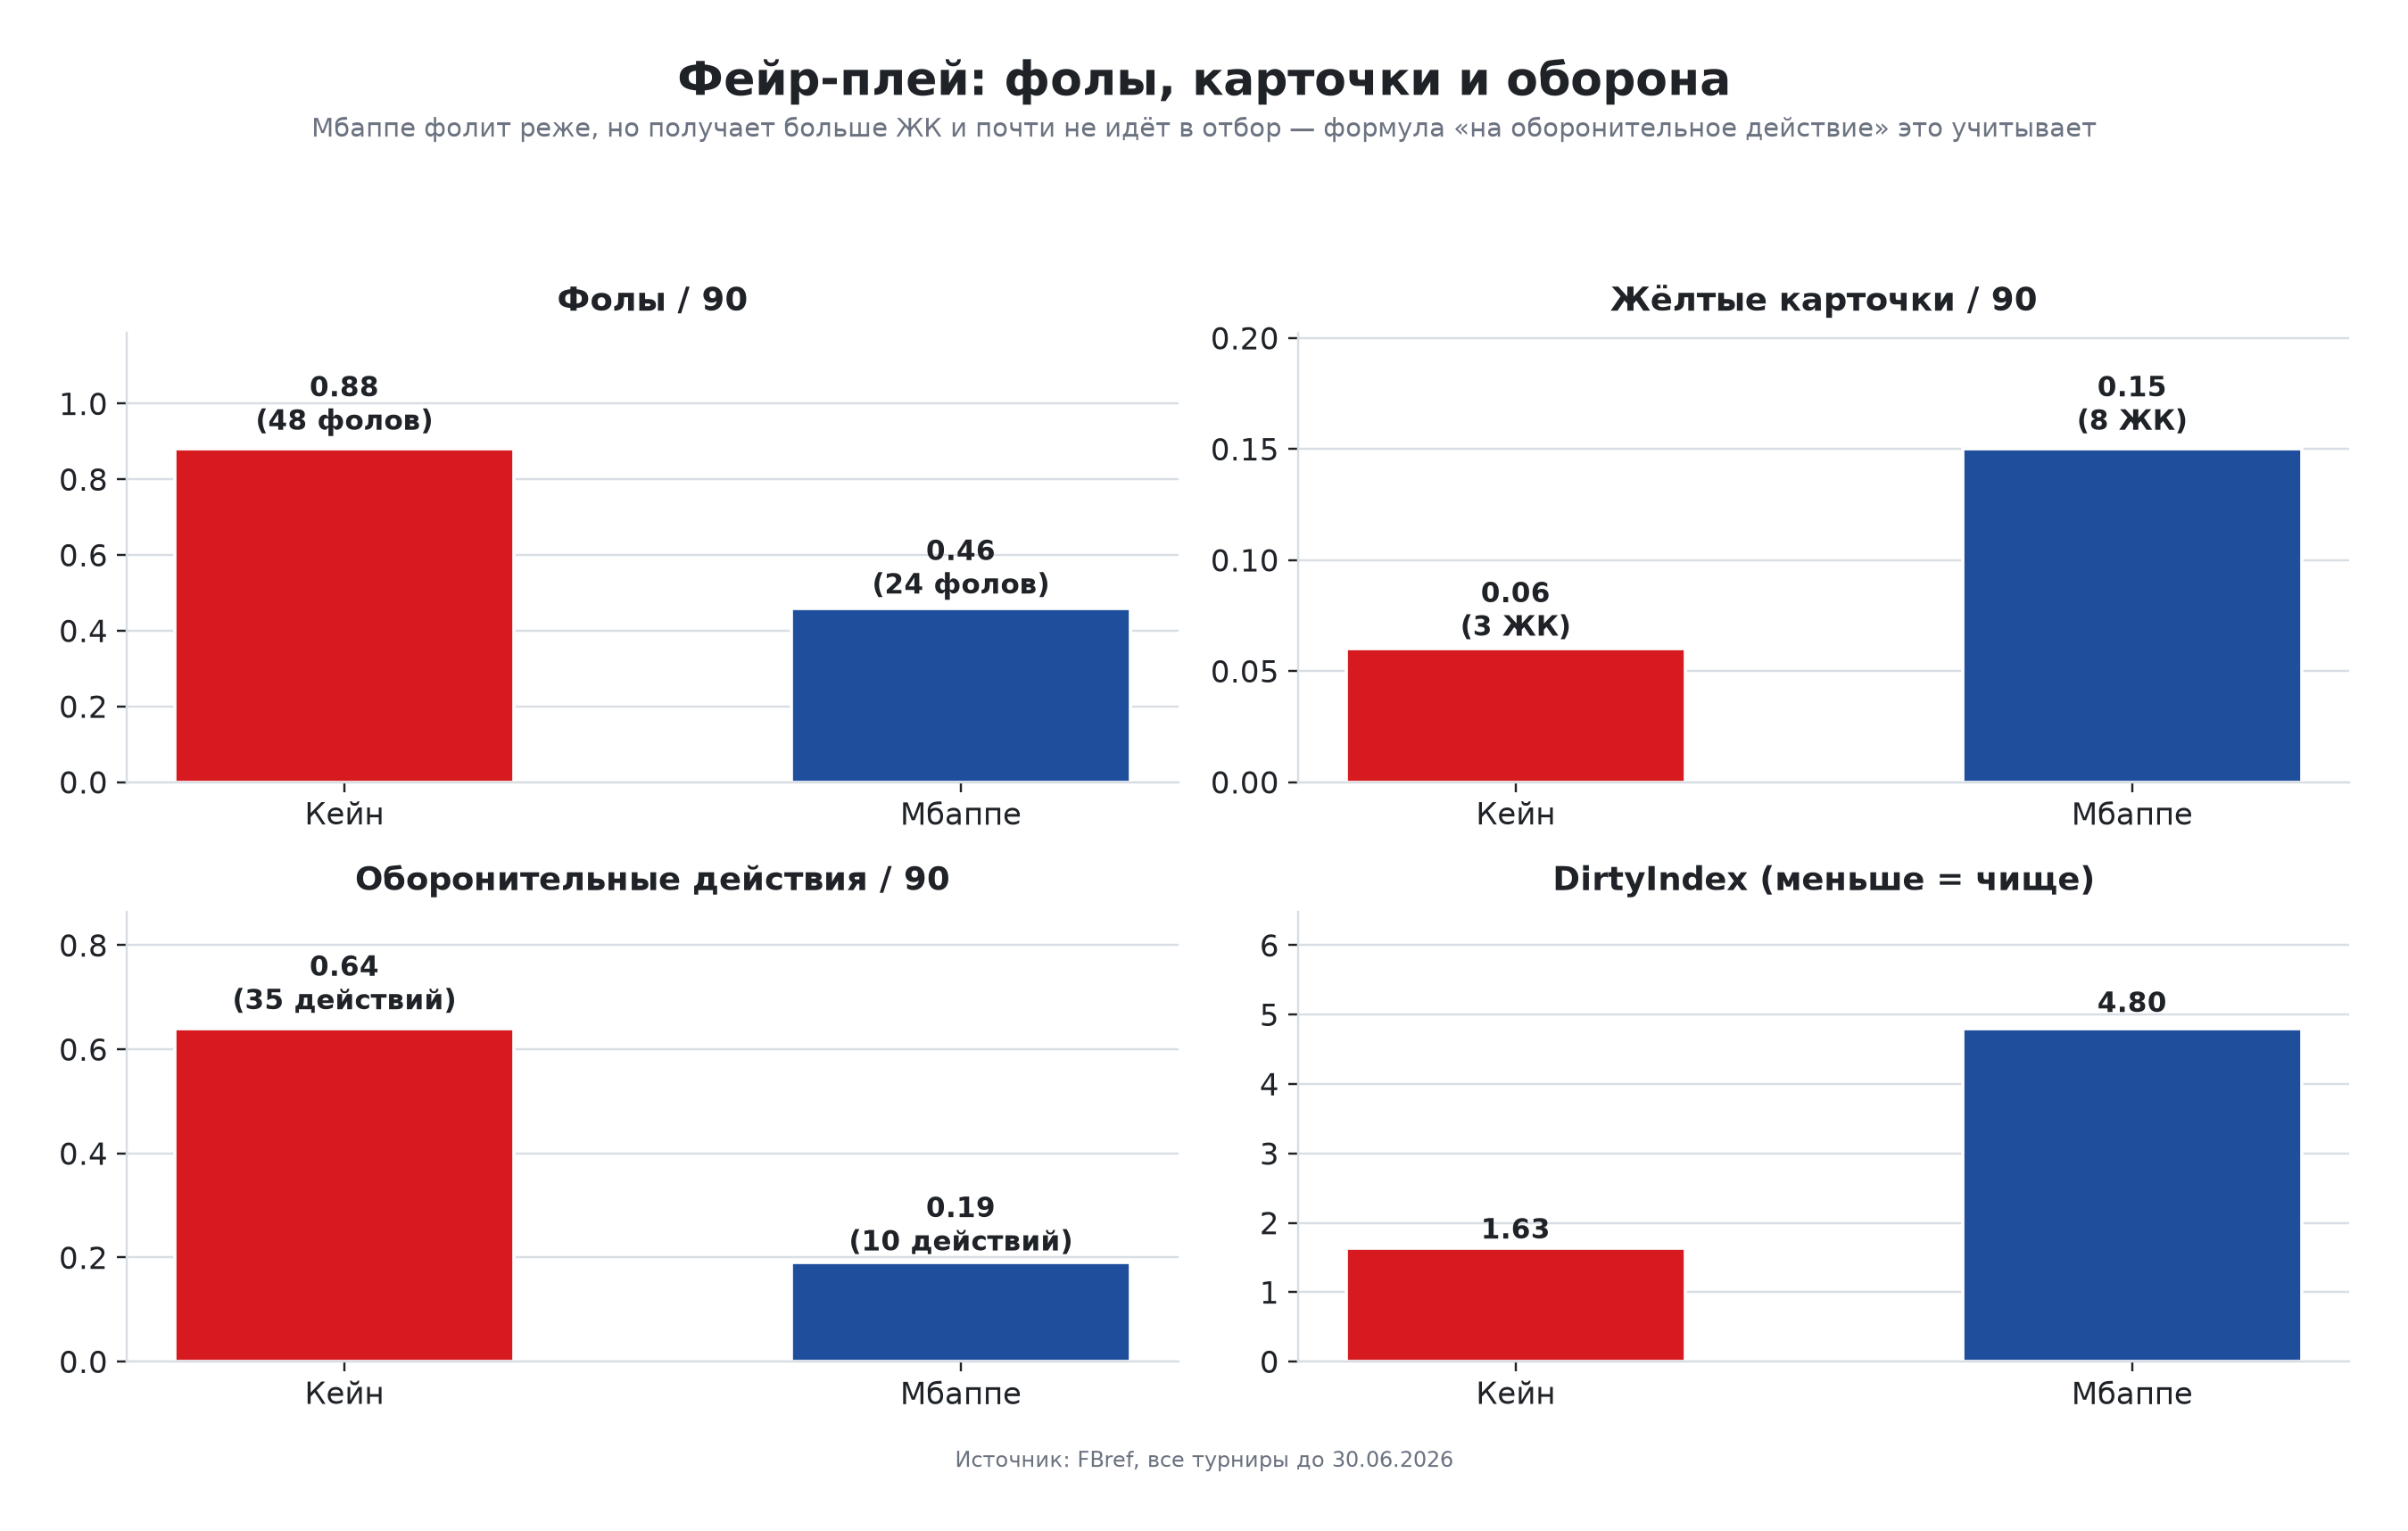

In [11]:
display(Image(filename=str(FIGURES["fair_play"])))

## 4. Итоговый счёт

| Блок | Кейн | Мбаппе |
|---|---:|---:|
| Result (20) | 20.0 | 13.3 |
| Creation (15) | 13.1 | 13.8 |
| Finishing (10) | 9.6 | 2.5 |
| Volume (5) | 4.2 | 4.6 |
| **Статистика (50)** | **46.9** | **34.2** |
| Команда (30) | 18.6 | 11.4 |
| Фейр-плей (20) | 13.8 | 6.2 |
| **Итого (100)** | **79.2** | **51.8** |

Кейн забирает результативность, конверсию, командные достижения и фейр-плей; Мбаппе - только создание моментов и вовлечённость,
причём с минимальным отрывом. Разрыв - **27.3 балла**.

In [12]:
final_scores = pd.read_csv("data/clean/scores.csv", index_col=0)
final_scores.index = ["Кейн", "Мбаппе"]
display(final_scores.style.format("{:.1f}"))

,Result (20),Creation (15),Finishing (10),Volume (5),Stats (50),Team (30),FairPlay (20),TOTAL (100)
Кейн,20.0,13.1,9.6,4.2,46.9,18.6,13.8,79.2
Мбаппе,13.3,13.8,2.5,4.6,34.2,11.4,6.2,51.8


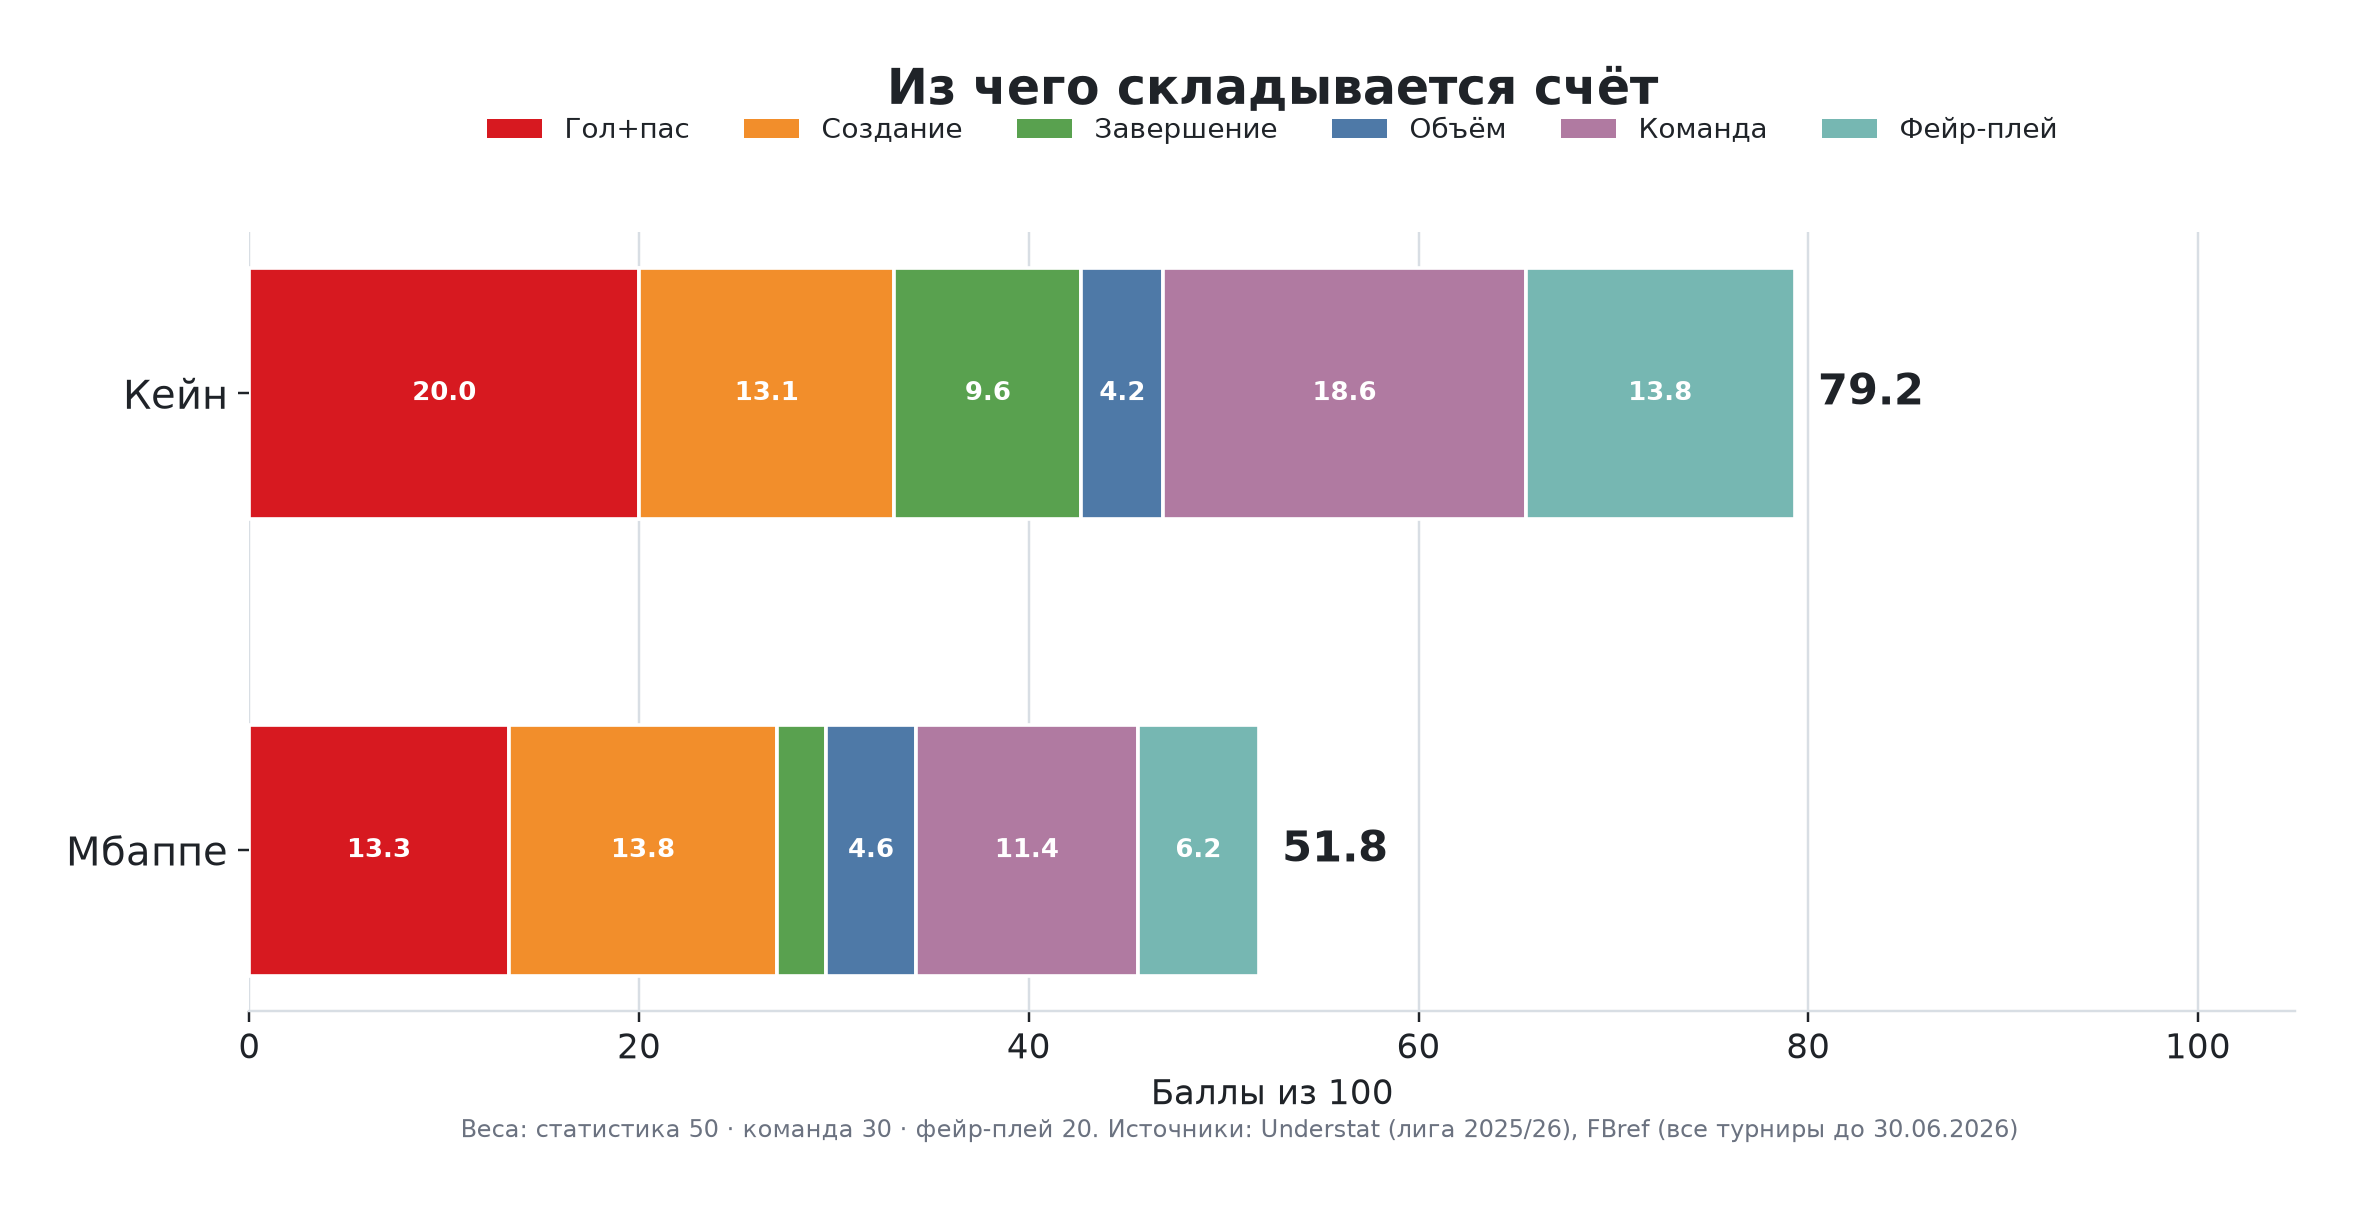

In [13]:
display(Image(filename=str(FIGURES["score_breakdown"])))

## 5. Чувствительность: что будет, если веса другие?

Проверяем два уровня:

1. **Сценарии**: только статистика, только команда, только фейр-плей, равные блоки,
   без команды, без фейр-плея, альтернативный пул, без Суперкубка, с карьерным рекордом, только трофеи.
2. **Сетки весов**: 81 комбинация основных блоков (статистика 40-60%, команда 20-40%, фейр-плей - остаток)
   и 70 комбинаций внутри статистики (Result 5-35, Creation 5-35, Finishing = 10, Volume = 50 - Result - Creation - 10).

Во всех сценариях и во всех комбинациях побеждает Кейн. Минимальный разрыв внутри статистики - **21.3 балла**
при Result = 5, Creation = 20, Finishing = 10, Volume = 15: даже почти полностью убрав результат,
перевес Кейна не исчезает. Оно и понятно - Кейн опережает Мбаппе во всех показателях, поэтому в данном конкретном случае веса победителя не изменят.

In [14]:
scenarios = pd.read_csv("data/clean/scores_sensitivity.csv")
scenarios = scenarios.rename(columns={
    "scenario": "Сценарий",
    "kane": "Кейн",
    "mbappe": "Мбаппе",
    "gap": "Разрыв",
    "winner": "Победитель",
    "note": "Комментарий",
}).set_index("Сценарий")
display(scenarios.round(1))

,Кейн,Мбаппе,Разрыв,Победитель,Комментарий
Сценарий,,,,,
База,79.20,51.80,27.30,Кейн,"50/30/20, перцентили, основной пул"
Старый min-max,80.00,20.00,60.00,Кейн,как в исходном scores.py: каждый блок 0/100
Только статистика,93.70,68.40,25.40,Кейн,веса перенормированы до 100
Только команда,61.90,38.10,23.80,Кейн,веса перенормированы до 100
Только фейр-плей,68.80,31.20,37.60,Кейн,веса перенормированы до 100
Равные блоки,74.80,45.90,28.90,Кейн,33/33/33
Без фейр-плея,79.40,54.70,24.70,Кейн,55/45/0
Без команды,86.30,57.20,29.00,Кейн,70/0/30
Альтернативный пул,76.50,42.90,33.60,Кейн,топ-10 по G+A/90 вместо топ-10 по голам


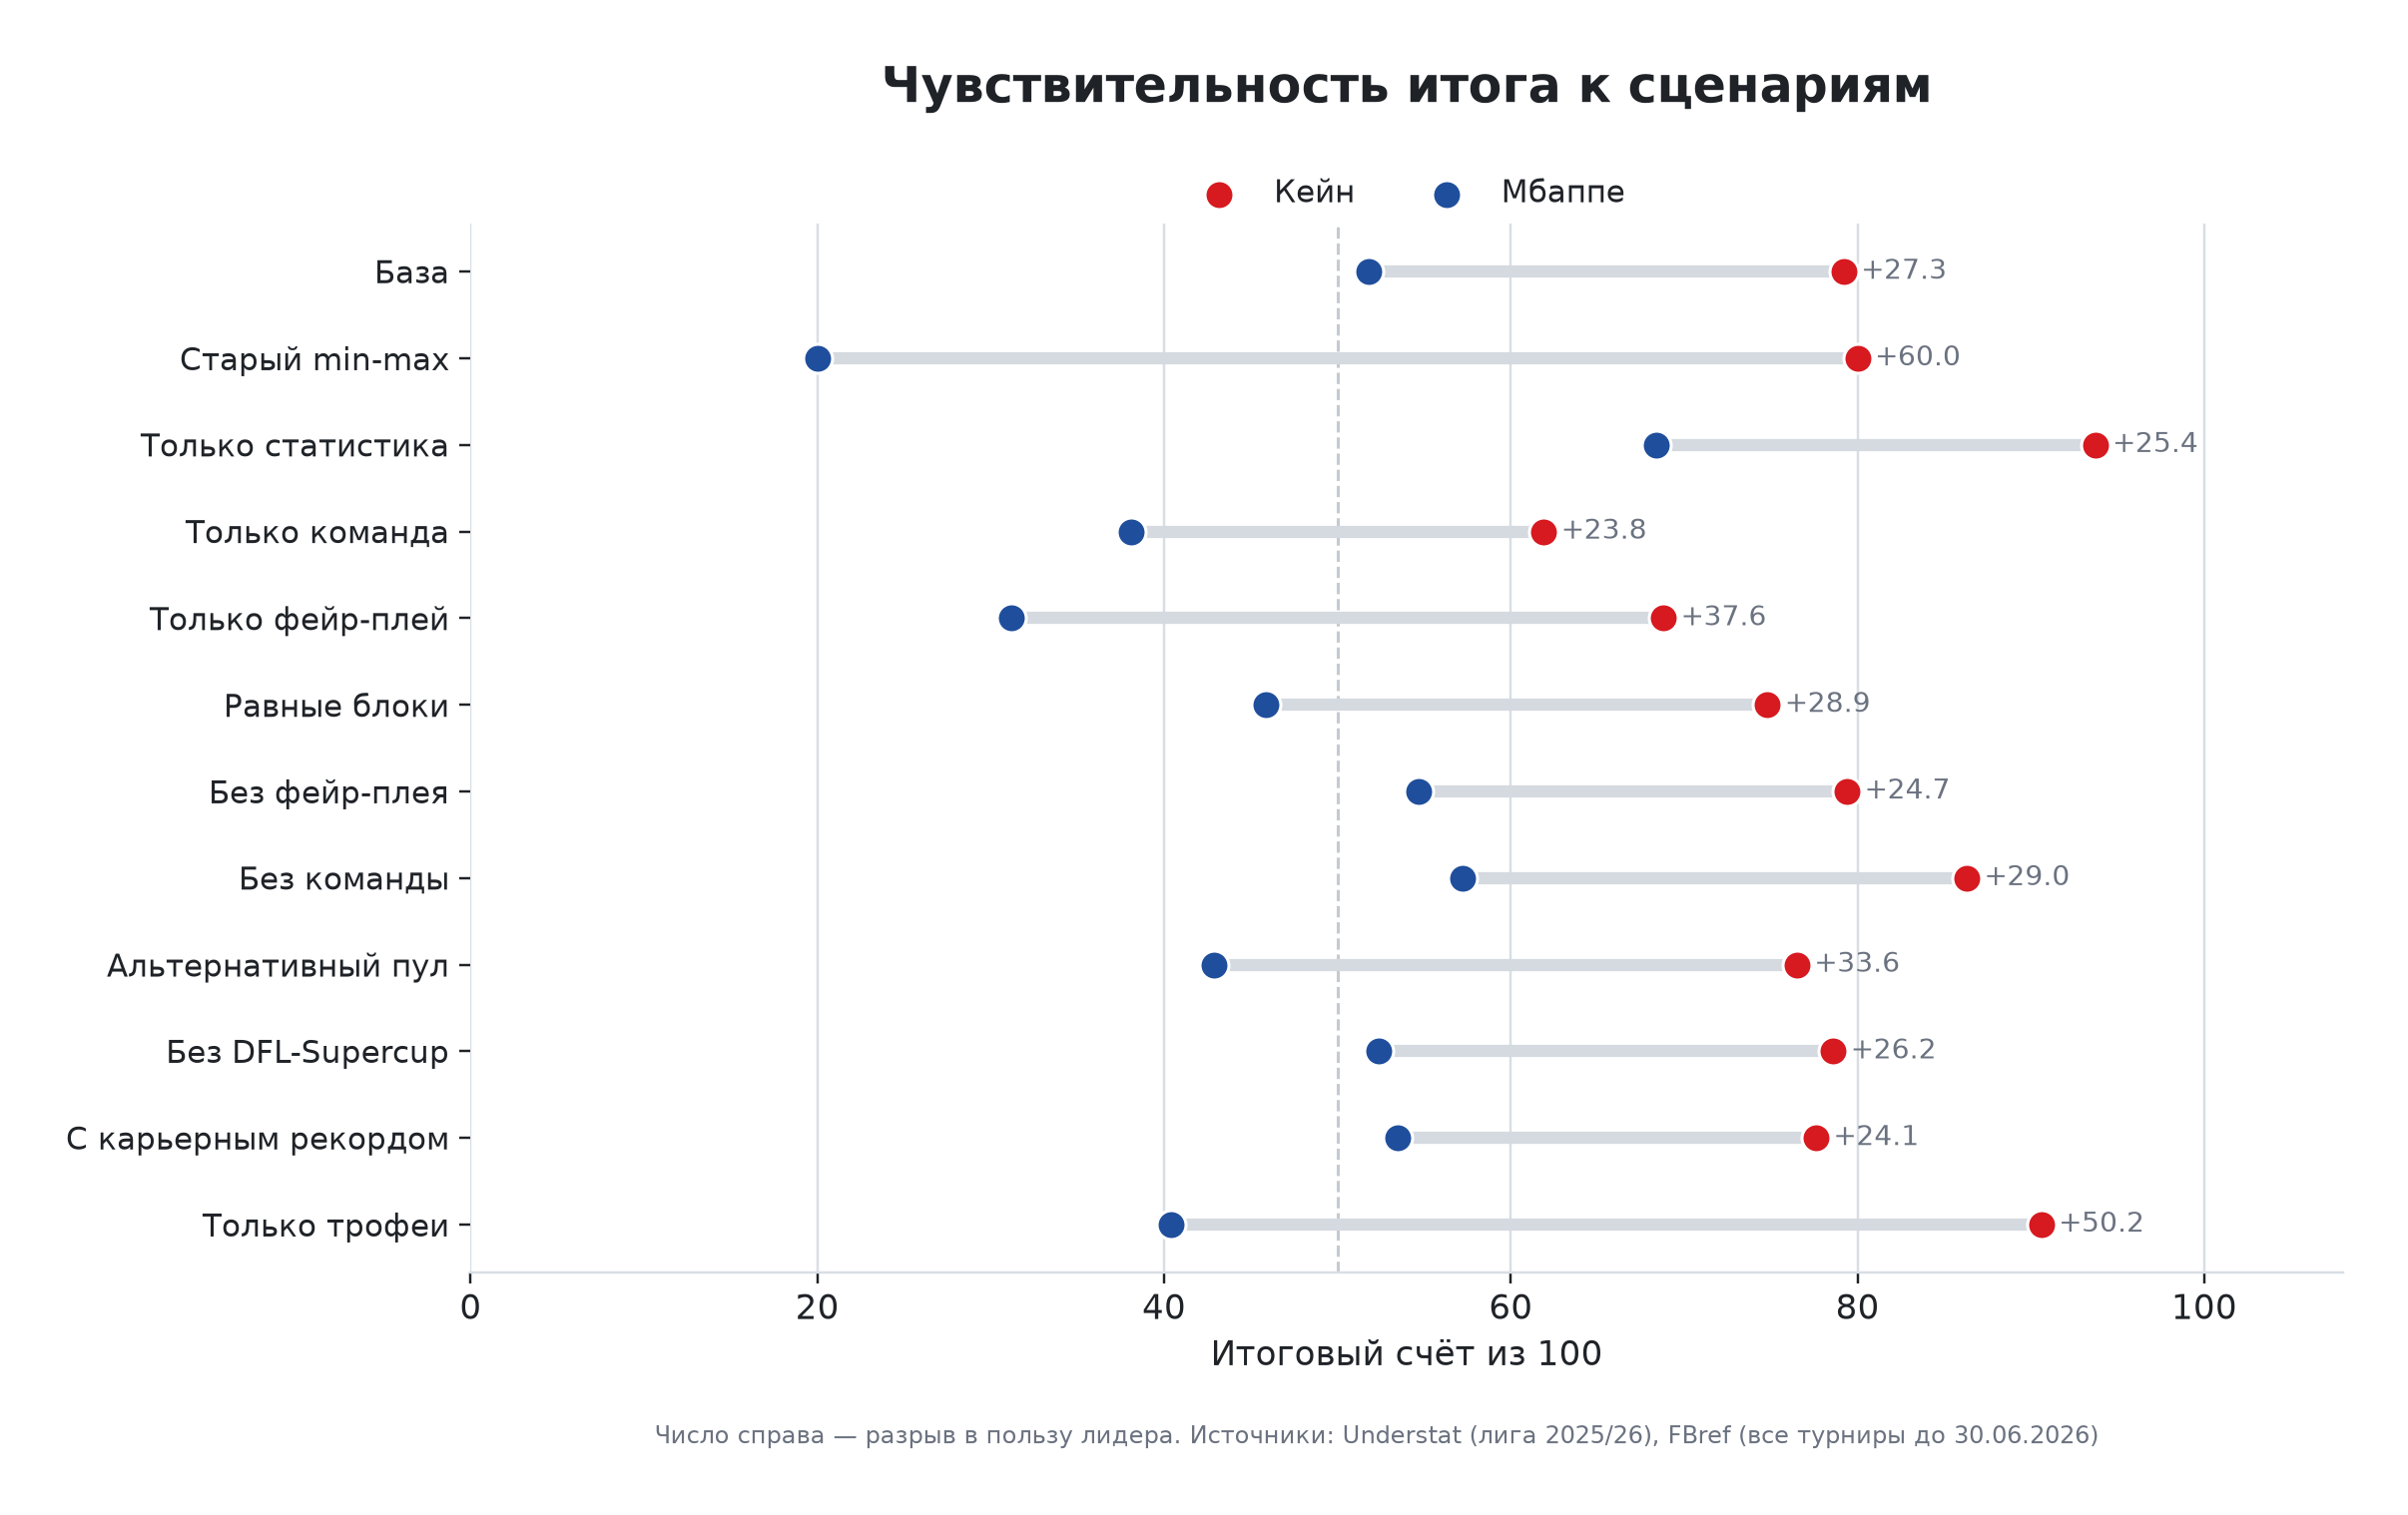

In [15]:
display(Image(filename=str(FIGURES["sensitivity_scenarios"])))

In [16]:
grid_stats = pd.read_csv("data/clean/sensitivity_grid_stats.csv")
grid_major = pd.read_csv("data/clean/sensitivity_grid_major.csv")

summary = pd.DataFrame({
    "Сетка": ["Основные блоки", "Внутри статистики"],
    "Комбинаций": [len(grid_major), len(grid_stats)],
    "Минимальный разрыв": [grid_major["gap"].min(), grid_stats["gap"].min()],
    "Максимальный разрыв": [grid_major["gap"].max(), grid_stats["gap"].max()],
    "Победители": [
        ", ".join(sorted(grid_major["winner"].unique())),
        ", ".join(sorted(grid_stats["winner"].unique())),
    ],
})
display(summary.set_index("Сетка").round(1))

,Комбинаций,Минимальный разрыв,Максимальный разрыв,Победители
Сетка,,,,
Основные блоки,81,24.70,30.00,Кейн
Внутри статистики,70,21.30,33.20,Кейн


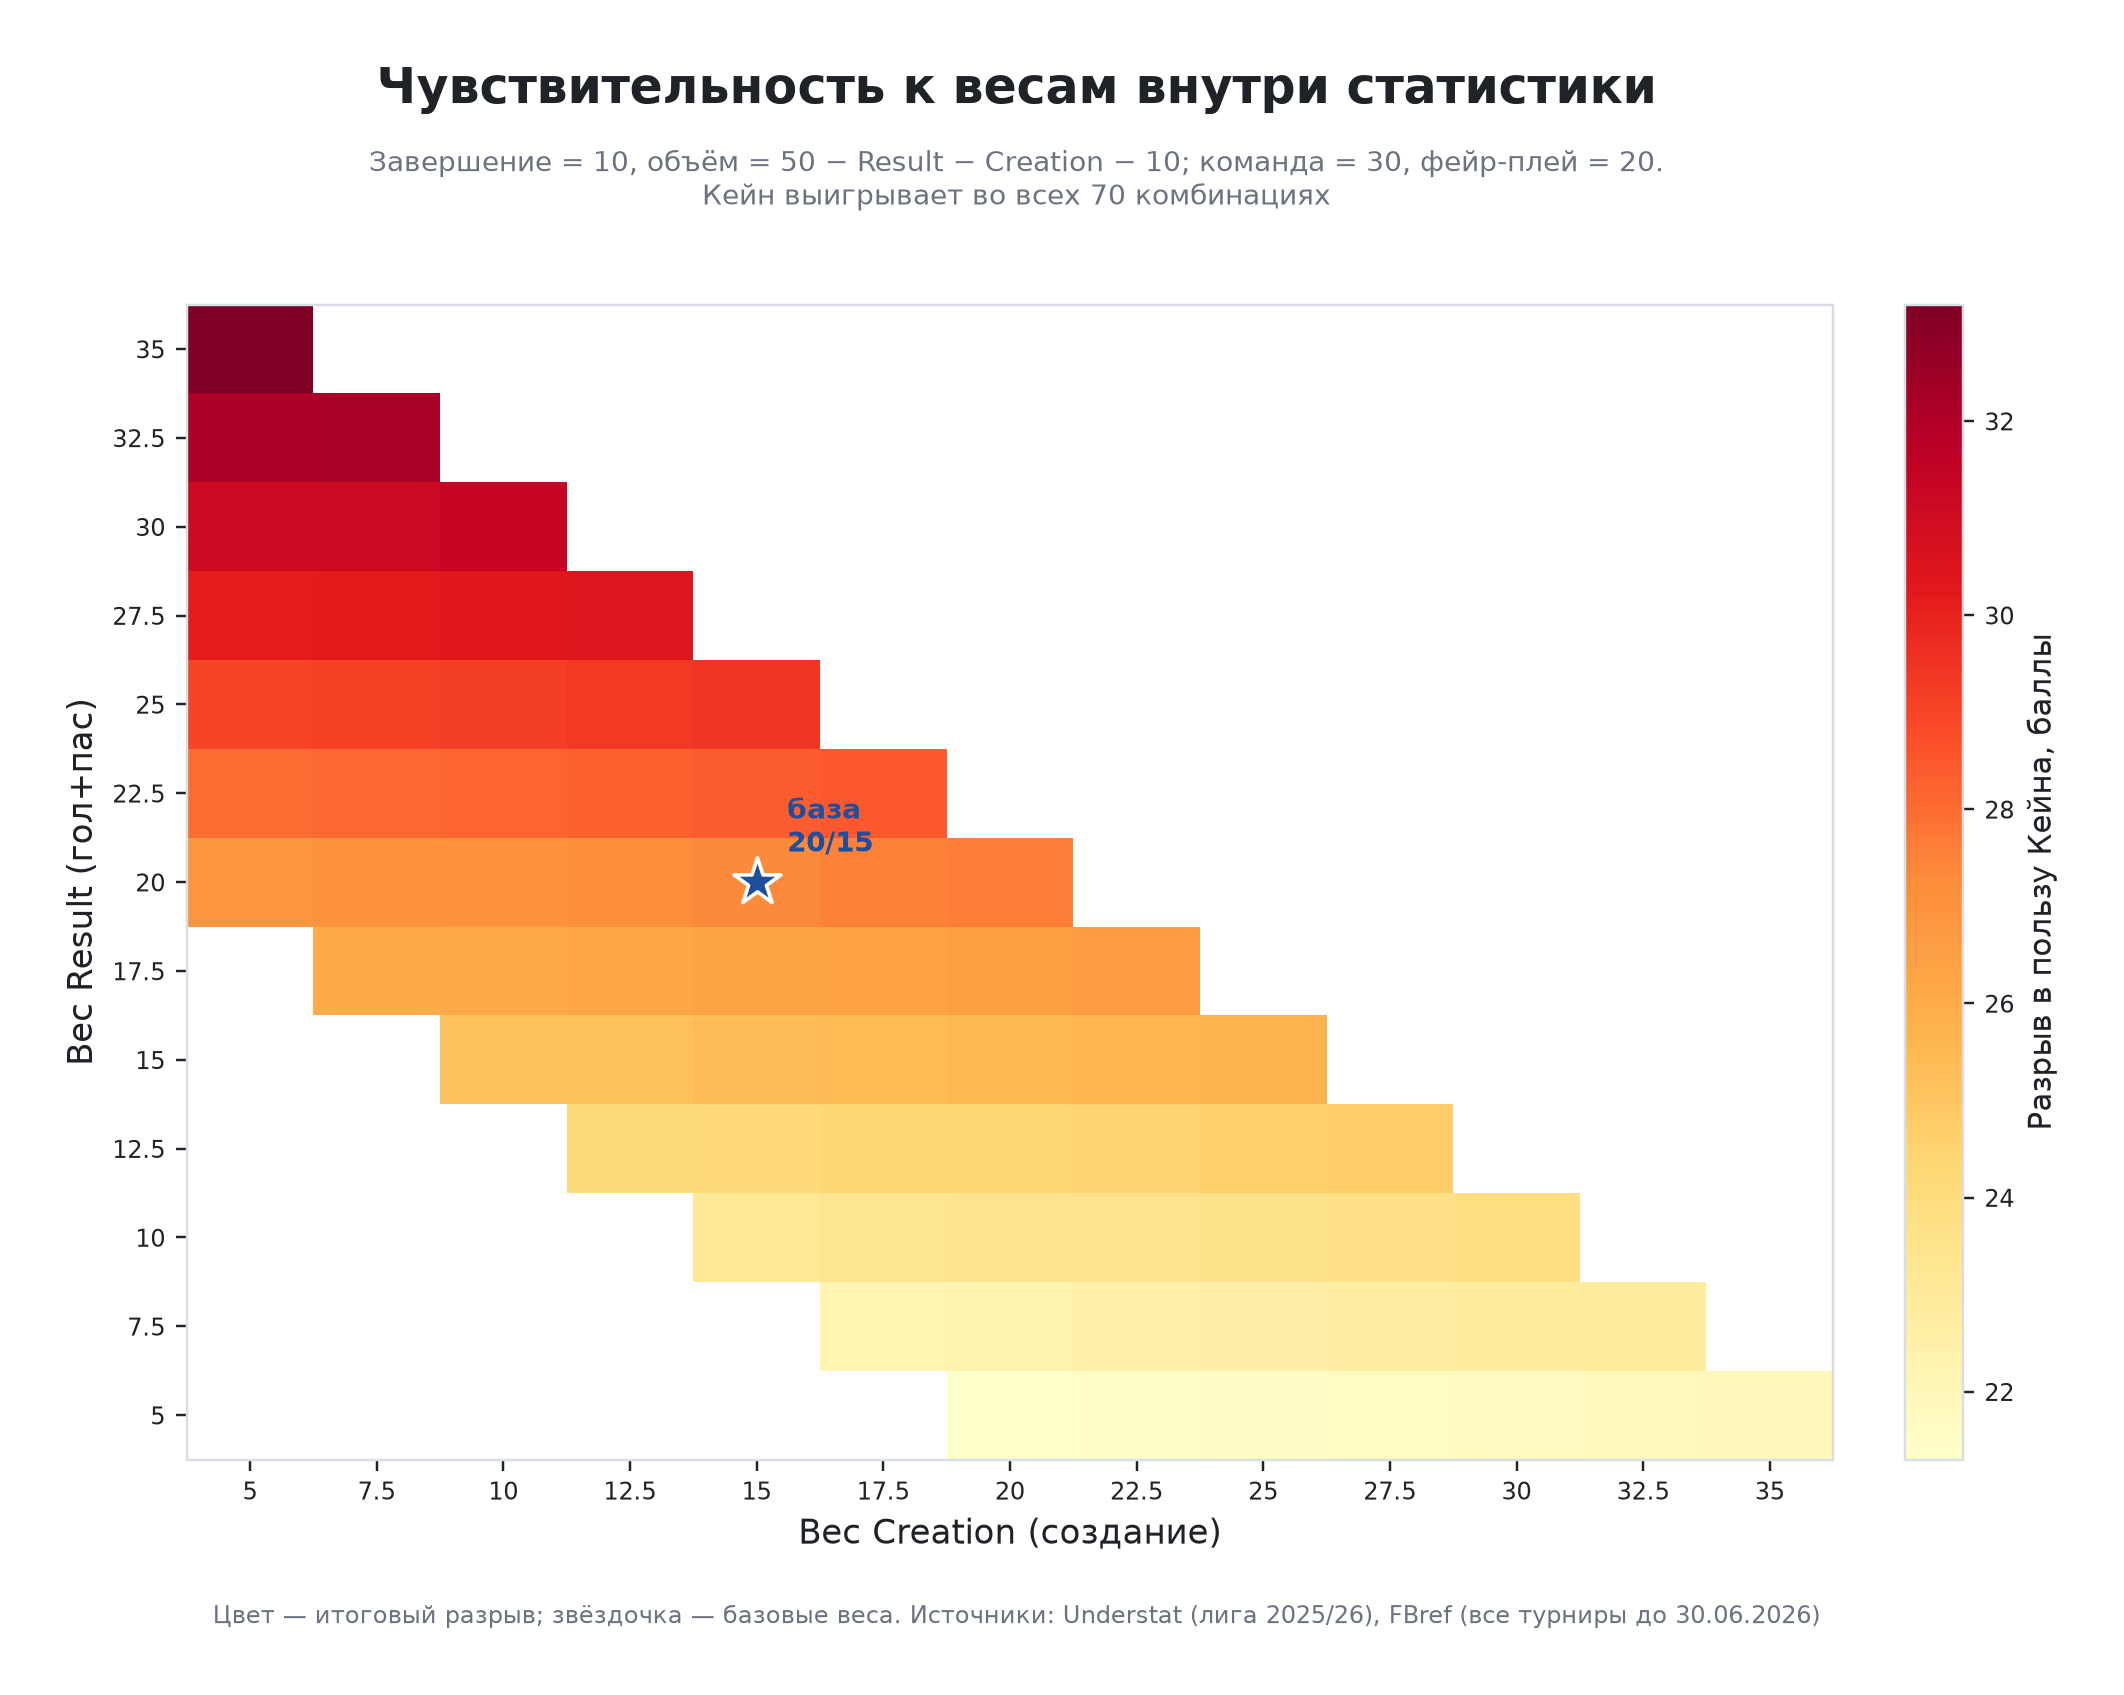

In [17]:
display(Image(filename=str(FIGURES["sensitivity_heatmap"])))

## 6. Выводы

1. **Кейн - сильнее по совокупности критериев.** 79.2 против 51.8. Он лучше в завершении
   (конверсия 24.1% против 12.4%, «голы - npxG» +4.75 против -2.11) и в результате
   (1.17 против 0.75 гола+паса без пенальти на 90).
2. **Мбаппе - не «слабее по всем пунктам».** Он лучше в создании (2.23 ключевые передачи на 90 против 1.51)
   и наносит больше ударов (4.70 против 4.08). Но эти преимущества дают ему лишь +0.7 в Creation и +0.4 в Volume.
3. **Командный блок** добавляет Кейну 18.6 против 11.4: 6 очков за трофеи (Бундеслига, Кубок Германии,
   Суперкубок) и 7 за индивидуальные награды. У Мбаппе 0 за трофеи и 8 за награды.
4. **Фейр-плей** - самый спорный блок, но он не создаёт победу Кейна: без него разрыв 24.7,
   с ним - 27.3. Формула лишь усиливает уже существующий перевес, потому что справедливо учитывает работоспособность и вклад игрока в оборонительные действия.
5. **Ответ устойчив (в рамках данной модели).** Кейн выигрывает все 12 сценариев, все 81 комбинацию основных весов
   и все 70 комбинаций внутри статистики. Минимальный разрыв - 21.3.
6. **Старая min-max нормировка** давала 80:20, потому что превращала любой перевес в 0/100.
   Перцентили и доли сохраняют величину разрыва, поэтому 79.2:51.8 - более честная картина.

### Ограничения

- Плей-офф ЧМ (включая полуфиналы) отсутствует в выгрузках FBref.
  Индивидуальный счёт от этого не зависит. Всё остальное - в рамках погрешности. Тем не менее, проговорить стоит.
- xG/xA есть только для лиги (Understat). Все турниры показаны без xG.
- Пул из 10 форвардов - мой личный выбор. Альтернативный пул по G+A/90 даёт 76.5:42.9,
  то есть ещё больший разрыв.
- Веса блоков субъективны. Поэтому они проверены сетками, а не объявлены «единственно верными».
- Карьерные рекорды не учитываются: это сравнение сезона, а не всей карьеры.

## 7. Воспроизводимость

Порядок запуска из корня проекта:

```bash
python load_clean.py data/raw/Kane --player "Harry Kane"
python load_clean.py data/raw/Mbappe --player "Kylian Mbappe"
python fetch_understat.py   # опционально: обновляет кэш Understat (нужна сеть)
python metrics.py           # per-90, перцентили, все турниры, фейр-плей
python scores.py            # баллы, блоки, сценарии, сетки чувствительности
python plots.py             # figures/*.png
```

Ноутбук сам вызывает `metrics.save_all()`, `scores.main()` и `plots.plot_all()`,
поэтому его можно выполнить целиком: **Run All**.

Основные выходы:

- `data/clean/metrics.csv` — 12 игроков, per-90 и перцентили;
- `data/clean/scores.csv` — итоговая таблица;
- `data/clean/scores_sensitivity.csv` — сценарии;
- `data/clean/sensitivity_grid_*.csv` — данные для сеток;
- `figures/*.png` — все графики.